# Replikasi Parsial: *Gradient-Boosted Tree* untuk Prediksi Penyakit Kardiovaskular dengan Apache Spark (PySpark MLlib)


---




### **Nama : Atika Adelia**

### **NIM : 123140172**


---



## Artikel acuan

Gupta, Y. K., & Kumari, S. (2021). Performance evaluation of distributed machine learning for cardiovascular disease prediction in Spark. *2021 5th International Conference on Trends in Electronics and Informatics (ICOEI)*, 1506–1512. IEEE. https://doi.org/10.1109/ICOEI51242.2021.9452955

**Dataset:** Ulianova, S. (n.d.). *Cardiovascular Disease dataset* [Data set]. Kaggle. https://www.kaggle.com/datasets/sulianova/cardiovascular-disease-dataset

## Tujuan

Mengulang bagian inti artikel, yaitu membangun pengklasifikasi **GBT** (`GBTClassifier`) pada Spark MLlib untuk memprediksi ada/tidaknya penyakit kardiovaskular (`cardio` = 1/0), lalu membandingkan hasilnya (AUC-ROC, *accuracy*, *precision*, *recall*, F1) dengan angka yang dilaporkan artikel. Empat model lain pada artikel (LR, DT, SVM, RF) **tidak** direplikasi.



## 1. Persiapan lingkungan

Artikel memakai Spark 2.4.7. Versi itu tidak kompatibel dengan Python dan Java pada Colab saat ini, sehingga replikasi ini memakai **PySpark 3.5.x** + **Java 17**. API `GBTClassifier`, `CrossValidator`, dan evaluator yang dipakai sama; perbedaan versi dicatat pada bagian 15.

In [32]:
import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from functools import reduce
from IPython.display import display

from pyspark.sql import SparkSession, functions as F
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.classification import GBTClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator
from pyspark.ml.functions import vector_to_array
from sklearn.metrics import roc_curve

In [29]:
# 1.1 Pasang Java 17 dan pustaka Python (cukup sekali per sesi Colab)
!apt-get install -y -qq openjdk-17-jdk-headless > /dev/null 2>&1
!pip install -q "pyspark>=3.5,<4" kagglehub

In [30]:
# 1.2 Atur JAVA_HOME dan catat versi seluruh komponen (syarat reprodusibilitas, panduan 4.2)
import os, glob, sys, subprocess

java_dirs = sorted(glob.glob("/usr/lib/jvm/java-17-openjdk-*"))
if not java_dirs:
    raise RuntimeError("Java 17 tidak ditemukan. Jalankan ulang sel instalasi (1.1).")
os.environ["JAVA_HOME"] = java_dirs[0]
os.environ["PATH"] = os.environ["JAVA_HOME"] + "/bin:" + os.environ["PATH"]

import numpy, pandas, matplotlib, sklearn, pyspark

java_ver = subprocess.run(["java", "-version"], capture_output=True, text=True).stderr.splitlines()[0]
print(f"PySpark      : {pyspark.__version__}")

PySpark      : 3.5.9


## 2. Konfigurasi eksperimen

Seluruh parameter dikumpulkan di satu sel. Nilai bertanda **[artikel]** diambil langsung dari artikel; nilai bertanda **[asumsi]** adalah keputusan saya karena artikel tidak merincinya (dibahas di bagian 15).

In [31]:
# Konfigurasi Parameter
SEED = 42

# Splitting Data
SAMPLE_FRACTION = 1.0
TRAIN_RATIO, TEST_RATIO = 0.7, 0.3
OUTLIER_STRATEGY = "median"

# Model Base Line
GBT_BASE = dict(maxIter=75, maxDepth=3)

# Tuning (Artikel Memakai ParamGridBuilder + CrossValidator, 5-fold)
RUN_CV = True
CV_FOLDS = 5
# Asumsi nilai baseline = 5
GRID_MAX_DEPTH = [3, 5, 7]
# Asumsi nilai baseline = 75
GRID_MAX_ITER = [50, 75]

# Penilaian Pembanding
PAPER_GBT_TABLE3 = {
    "AUC-ROC (%)": 80.02, "Accuracy (%)": 73.20, "Precision (%)": 76.79,
    "Recall (%)": 66.10, "F1-score (%)": 71.05,
}
PAPER_GBT_CM = dict(tn=5237, fp=1660, fn=2012, tp=4794)
PAPER_TEST_SIZE = sum(PAPER_GBT_CM.values())

OUTPUT_DIR = "/content/results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

## 3. Inisialisasi SparkSession (mode lokal)

Spark dijalankan dengan `local[*]`: seluruh *executor* berjalan di dalam satu mesin Colab. Ini sesuai skema replikasi parsial (mode lokal), tetapi artinya eksperimen ini **tidak** menguji skalabilitas klaster.

In [33]:
spark = (SparkSession.builder
         .master("local[*]")
         .appName("Replikasi-GBT-Cardiovascular")
         .config("spark.driver.memory", "4g")
         .config("spark.sql.shuffle.partitions", "8")
         .config("spark.sql.ansi.enabled", "false")
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

# Catatan waktu eksekusi
timings = {}
print("Spark version       :", spark.version)
print("Master              :", spark.sparkContext.master)
print("Default parallelism :", spark.sparkContext.defaultParallelism, "core")

Spark version       : 3.5.9
Master              : local[*]
Default parallelism : 48 core


## 4. Memuat dataset

Dataset diunduh dari Kaggle dengan `kagglehub`. Jika unduhan otomatis gagal (mis. perlu autentikasi), sel akan meminta Anda mengunggah `cardio_train.csv` secara manual. Berkas memakai pemisah titik koma (`;`).

Kolom (artikel, Tabel 1): `id`, `age` (hari), `gender` (1 = perempuan, 2 = laki-laki), `height` (cm), `weight` (kg), `ap_hi` (tekanan sistolik), `ap_lo` (tekanan diastolik), `cholesterol` (1–3), `gluc` (1–3), `smoke`, `alco`, `active` (biner), dan target `cardio` (0/1).

In [34]:
def locate_dataset_csv() -> str:
    try:
        import kagglehub
        folder = kagglehub.dataset_download("sulianova/cardiovascular-disease-dataset")
        hits = glob.glob(os.path.join(folder, "**", "cardio_train.csv"), recursive=True)
        if not hits:
            raise FileNotFoundError("cardio_train.csv tidak ditemukan di folder unduhan")
        return hits[0]
    except Exception as err:
        print(f"Unduhan otomatis gagal ({type(err).__name__}: {err})")
        from google.colab import files
        uploaded = files.upload()
        name = next((n for n in uploaded if n.lower().endswith(".csv")), None)
        if name is None:
            raise RuntimeError("Tidak ada berkas .csv yang diunggah.")
        return os.path.abspath(name)


CSV_PATH = locate_dataset_csv()
print("Dataset :", CSV_PATH)

df_raw = spark.read.csv(f"file://{CSV_PATH}", header=True, sep=";", inferSchema=True)

# replikasi parsial pada subset data
if SAMPLE_FRACTION < 1.0:
    df_raw = df_raw.sample(withReplacement=False, fraction=SAMPLE_FRACTION, seed=SEED)
df_raw = df_raw.cache()

n_raw = df_raw.count()
print(f"Jumlah baris : {n_raw:,}")
print(f"Jumlah kolom : {len(df_raw.columns)}")

Using Colab cache for faster access to the 'cardiovascular-disease-dataset' dataset.
Dataset : /kaggle/input/cardiovascular-disease-dataset/cardio_train.csv
Jumlah baris : 70,000
Jumlah kolom : 13


## 5. Eksplorasi data (EDA)

Tujuan EDA di sini terbatas: memeriksa skema, nilai kosong, rentang nilai (untuk menentukan aturan pembersihan), dan keseimbangan kelas target (artikel, Gambar 1).

In [35]:
# 5.1 Skema dan contoh data
df_raw.printSchema()
display(df_raw.limit(5).toPandas())

root
 |-- id: integer (nullable = true)
 |-- age: integer (nullable = true)
 |-- gender: integer (nullable = true)
 |-- height: integer (nullable = true)
 |-- weight: double (nullable = true)
 |-- ap_hi: integer (nullable = true)
 |-- ap_lo: integer (nullable = true)
 |-- cholesterol: integer (nullable = true)
 |-- gluc: integer (nullable = true)
 |-- smoke: integer (nullable = true)
 |-- alco: integer (nullable = true)
 |-- active: integer (nullable = true)
 |-- cardio: integer (nullable = true)



,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


In [36]:
# 5.2 Nilai kosong per kolom
null_counts = df_raw.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in df_raw.columns]).toPandas()
print("Jumlah nilai kosong per kolom:")
display(null_counts)

Jumlah nilai kosong per kolom:


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [37]:
# 5.3 Rentang nilai variabel numerik: min / kuartil / maks
# (nilai ekstrem pada height, weight, ap_hi, ap_lo menjadi dasar aturan pembersihan)
num_cols = ["age", "height", "weight", "ap_hi", "ap_lo"]
display(df_raw.select(num_cols).summary("min", "25%", "50%", "75%", "max").toPandas())

,summary,age,height,weight,ap_hi,ap_lo
0,min,10798,55,10.0,-150,-70
1,25%,17664,159,65.0,120,80
2,50%,19703,165,72.0,120,80
3,75%,21326,170,82.0,140,90
4,max,23713,250,200.0,16020,11000


In [38]:
# 5.4 Domain nilai variabel kategorikal / biner
for c in ["gender", "cholesterol", "gluc", "smoke", "alco", "active", "cardio"]:
    vals = sorted(r[0] for r in df_raw.select(c).distinct().collect())
    print(f"{c:12s}: {vals}")

gender      : [1, 2]
cholesterol : [1, 2, 3]
gluc        : [1, 2, 3]
smoke       : [0, 1]
alco        : [0, 1]
active      : [0, 1]
cardio      : [0, 1]


 cardio  count
      0  35021
      1  34979

Pada Artikel: cardio=1 berjumlah 34.979 baris, cardio=0 berjumlah 35.021 baris.


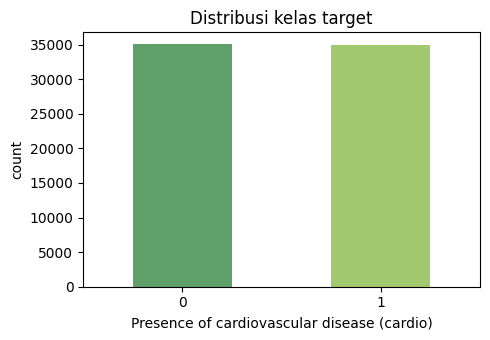

In [39]:
# 5.5 Distribusi kelas target
class_pdf = df_raw.groupBy("cardio").count().orderBy("cardio").toPandas()
print(class_pdf.to_string(index=False))
print("\nPada Artikel: cardio=1 berjumlah 34.979 baris, cardio=0 berjumlah 35.021 baris.")

ax = class_pdf.plot.bar(x="cardio", y="count", legend=False, rot=0,
                        color=["#5fa06a", "#a3c96f"], figsize=(5, 3.5))
ax.set_xlabel("Presence of cardiovascular disease (cardio)")
ax.set_ylabel("count")
ax.set_title("Distribusi kelas target")

plt.tight_layout()
plt.show()

## 6. Pembersihan data (artikel III-A)

Artikel menyatakan tiga langkah: (1) membuang kolom `id` karena tidak relevan, (2) membuang baris duplikat, dan (3) "mengganti nilai yang aneh" (*replaced the strange value*). Langkah (3) **tidak dirinci** pada artikel, sehingga saya mendefinisikannya sebagai berikut **[asumsi]**:

| Kolom | Rentang dianggap valid | Dasar |
|---|---|---|
| `height` | 120 – 220 cm | tinggi badan orang dewasa yang masuk akal |
| `weight` | 30 – 200 kg | berat badan orang dewasa yang masuk akal |
| `ap_hi` | 70 – 250 mmHg | tekanan sistolik yang mungkin terukur |
| `ap_lo` | 40 – 200 mmHg | tekanan diastolik yang mungkin terukur |

Nilai di luar rentang **diganti dengan median** kolom tersebut (`OUTLIER_STRATEGY = "median"`, sesuai kata "replaced"), atau barisnya dibuang bila `OUTLIER_STRATEGY = "drop"`. Selain itu, baris dengan `ap_hi < ap_lo` (diastolik lebih besar dari sistolik, kemungkinan tertukar saat input) diperbaiki dengan menukar keduanya.

In [40]:
VALID_RANGES = {"height": (120, 220), "weight": (30, 200), "ap_hi": (70, 250), "ap_lo": (40, 200)}

# 6.1 Buang kolom id, samakan tipe data menjadi double
df = df_raw.drop("id")
df = df.select([F.col(c).cast("double").alias(c) for c in df.columns])

# 6.2 Buang baris duplikat
n_before_dedup = df.count()
df = df.dropDuplicates()
n_dupes = n_before_dedup - df.count()

# 6.3 Hitung nilai di luar rentang (sebelum diperbaiki)
invalid_counts = df.select(
    [F.sum((~F.col(c).between(lo, hi)).cast("int")).alias(c) for c, (lo, hi) in VALID_RANGES.items()]
).toPandas().iloc[0].to_dict()
n_bp_inverted = df.filter(F.col("ap_hi") < F.col("ap_lo")).count()

# 6.4 Tangani nilai tak wajar
if OUTLIER_STRATEGY == "median":
    medians = {}
    for c, (lo, hi) in VALID_RANGES.items():
        medians[c] = df.filter(F.col(c).between(lo, hi)).approxQuantile(c, [0.5], 0.001)[0]
        df = df.withColumn(c, F.when(F.col(c).between(lo, hi), F.col(c)).otherwise(F.lit(medians[c])))
    print("Median pengganti:", medians)
elif OUTLIER_STRATEGY == "drop":
    valid_all = reduce(lambda a, b: a & b, [F.col(c).between(lo, hi) for c, (lo, hi) in VALID_RANGES.items()])
    df = df.filter(valid_all)
else:
    raise ValueError("OUTLIER_STRATEGY harus 'median' atau 'drop'")

# 6.5 Perbaiki tekanan darah tertukar
df = (df.withColumn("_hi", F.greatest("ap_hi", "ap_lo"))
        .withColumn("_lo", F.least("ap_hi", "ap_lo"))
        .drop("ap_hi", "ap_lo")
        .withColumnRenamed("_hi", "ap_hi")
        .withColumnRenamed("_lo", "ap_lo"))

df_clean = df.cache()
n_clean = df_clean.count()

print(f"\nBaris Sebelum pembersihan        : {n_raw:,}")
print(f"Baris duplikat dibuang             : {n_dupes:,}")
print(f"Nilai di luar rentang (sebelum)    : {invalid_counts}")
print(f"Baris ap_hi < ap_lo (sebelum)      : {n_bp_inverted:,}")
print(f"Strategi                           : {OUTLIER_STRATEGY}")
print(f"Baris setelah pembersihan          : {n_clean:,}")

Median pengganti: {'height': 165.0, 'weight': 72.0, 'ap_hi': 120.0, 'ap_lo': 80.0}

Baris Sebelum pembersihan        : 70,000
Baris duplikat dibuang             : 24
Nilai di luar rentang (sebelum)    : {'height': 53, 'weight': 7, 'ap_hi': 229, 'ap_lo': 1012}
Baris ap_hi < ap_lo (sebelum)      : 1,234
Strategi                           : median
Baris setelah pembersihan          : 69,976


In [41]:
# 6.6 Verifikasi: rentang setelah pembersihan
display(df_clean.select("height", "weight", "ap_hi", "ap_lo").summary("min", "50%", "max").toPandas())
print("Masih ada ap_hi < ap_lo? ->", df_clean.filter(F.col("ap_hi") < F.col("ap_lo")).count(), "baris")

,summary,height,weight,ap_hi,ap_lo
0,min,120.0,30.0,70.0,40.0
1,50%,165.0,72.0,120.0,80.0
2,max,207.0,200.0,240.0,182.0


Masih ada ap_hi < ap_lo? -> 0 baris


## 7. Praproses data (artikel III-B)

Artikel menyebut: *feature extraction* untuk membuat fitur baru, lalu `VectorAssembler` untuk mengubah fitur menjadi vektor, kemudian `StandardScaler`. Fitur baru tidak dirinci, sehingga saya membuat dua fitur turunan yang lazim pada data ini **[asumsi]**:

- `age_years` = `age` (hari) / 365,25, dibulatkan ke bawah (kolom `age` dalam hari lalu dibuang karena redundan);
- `bmi` = `weight` / (`height` / 100)².

Kolom target `cardio` dinamai `label` (sesuai `labelCol="label"` pada kode artikel). `StandardScaler` memakai pengaturan bawaan Spark (`withStd=True`, `withMean=False`).

> Urutan pada artikel (Gambar 2) adalah praproses **dahulu**, baru pembagian latih/uji; notebook ini mengikuti urutan tersebut. Untuk model berbasis pohon seperti GBT, penskalaan tidak mengubah hasil (pohon invarian terhadap transformasi monoton), sehingga tidak ada kebocoran data yang berarti dari langkah ini.

In [42]:
FEATURE_COLS = ["age_years", "gender", "height", "weight", "ap_hi", "ap_lo",
                "cholesterol", "gluc", "smoke", "alco", "active", "bmi"]

# 7.1 Feature extraction
df_fe = (df_clean
         .withColumn("age_years", F.floor(F.col("age") / 365.25))
         .withColumn("bmi", F.col("weight") / F.pow(F.col("height") / 100.0, 2))
         .drop("age")
         .withColumnRenamed("cardio", "label"))

# 7.2 VectorAssembler ke StandardScaler
assembler = VectorAssembler(inputCols=FEATURE_COLS, outputCol="features")
scaler = StandardScaler(inputCol="features", outputCol="features_scaled", withStd=True, withMean=False)
prep_model = Pipeline(stages=[assembler, scaler]).fit(df_fe)

# cache agar randomSplit
df_ml = prep_model.transform(df_fe).select("features_scaled", "label").cache()
print(f"Jumlah fitur: {len(FEATURE_COLS)} -> {FEATURE_COLS}")
print(f"Baris siap model: {df_ml.count():,}")
display(df_ml.limit(3).toPandas())

Jumlah fitur: 12 -> ['age_years', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'bmi']
Baris siap model: 69,976


,features_scaled,label
0,"[8.72423209061684, 2.0970413933508474, 20.0655...",1.0
1,"[8.872100431135769, 2.0970413933508474, 19.813...",0.0
2,"[7.541285366465403, 4.194082786701695, 21.8323...",0.0


## 8. Pembagian data latih dan uji

Pembagian 70% / 30% dengan `randomSplit` (artikel menyebut rasio ini, tetapi tidak menyebut *seed*; saya memakai `SEED` tetap agar hasil dapat diulang).

In [43]:
train_df, test_df = df_ml.randomSplit([TRAIN_RATIO, TEST_RATIO], seed=SEED)
train_df, test_df = train_df.cache(), test_df.cache()
n_train, n_test = train_df.count(), test_df.count()

print(f"Data latih : {n_train:,} baris ({n_train / (n_train + n_test):.1%})")
print(f"Data uji   : {n_test:,} baris ({n_test / (n_train + n_test):.1%})")
print(f"Pada artikel, ukuran data uji (jumlah confusion matrix) = {PAPER_TEST_SIZE:,}")

dist = pd.concat({"latih": train_df.groupBy("label").count().toPandas().set_index("label")["count"],
                  "uji": test_df.groupBy("label").count().toPandas().set_index("label")["count"]}, axis=1)
print("\nDistribusi kelas per subset:")
display(dist)

Data latih : 49,293 baris (70.4%)
Data uji   : 20,683 baris (29.6%)
Pada artikel, ukuran data uji (jumlah confusion matrix) = 13,703

Distribusi kelas per subset:


,latih,uji
label,,
1.0,24604,10368
0.0,24689,10315


## 9. Model GBT baseline (artikel, Gambar 7)

Konfigurasi persis seperti kode pada Gambar 7 artikel: `GBTClassifier(labelCol='label', maxIter=75, maxDepth=3)`; parameter lain memakai nilai bawaan Spark (`stepSize=0.1`, `maxBins=32`, *loss* logistik).

Satu catatan: kode GBT pada Gambar 7 tidak menyebut `featuresCol`, jadi artikel memakai kolom bawaan `features` (tanpa penskalaan), sedangkan model lain memakai `features_scaled`. Di sini GBT memakai `features_scaled`; karena pohon tidak terpengaruh skala, hasilnya setara.

In [44]:
gbt = GBTClassifier(featuresCol="features_scaled", labelCol="label", seed=SEED, **GBT_BASE)

t0 = time.perf_counter()
gbt_model = gbt.fit(train_df)
timings["gbt_baseline_fit_s"] = time.perf_counter() - t0

print(f"Parameter  : maxIter={gbt.getMaxIter()}, maxDepth={gbt.getMaxDepth()}, stepSize={gbt.getStepSize()}")
print(f"Jumlah pohon pada ensemble : {len(gbt_model.trees)}")
print(f"Waktu pelatihan            : {timings['gbt_baseline_fit_s']:.1f} detik")

Parameter  : maxIter=75, maxDepth=3, stepSize=0.1
Jumlah pohon pada ensemble : 75
Waktu pelatihan            : 6.3 detik


## 10. Evaluasi model baseline

Metrik mengikuti artikel (persamaan 1–4), dengan kelas positif = `cardio` 1:

$$Accuracy = \frac{TP+TN}{TP+FP+TN+FN} \qquad Precision = \frac{TP}{TP+FP} \qquad Recall = \frac{TP}{TP+FN} \qquad F1 = \frac{2}{\frac{1}{Recall}+\frac{1}{Precision}}$$

AUC-ROC dihitung dengan `BinaryClassificationEvaluator` (metrik bawaan `areaUnderROC`), seperti pada artikel. *Confusion matrix* dihitung langsung di Spark dengan `groupBy` (tanpa `collect()` seluruh data ke *driver* seperti pada kode artikel), sehingga tetap efisien untuk data besar.

In [45]:
# Menghitung metrik
def metrics_from_cm(cm: np.ndarray) -> dict:
    tn, fp, fn, tp = (int(v) for v in np.asarray(cm).ravel())
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    return {"tn": tn, "fp": fp, "fn": fn, "tp": tp,
            "accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1}


# Evaluasi Model
def evaluate_model(model, data):
    pred = model.transform(data).cache()

    auc_roc = BinaryClassificationEvaluator(labelCol="label", rawPredictionCol="rawPrediction",
                                            metricName="areaUnderROC").evaluate(pred)
    auc_pr = BinaryClassificationEvaluator(labelCol="label", rawPredictionCol="rawPrediction",
                                           metricName="areaUnderPR").evaluate(pred)

    cm = np.zeros((2, 2), dtype=int)
    for row in pred.groupBy("label", "prediction").count().collect():
        cm[int(row["label"]), int(row["prediction"])] = int(row["count"])

    m = metrics_from_cm(cm)
    m.update({"auc_roc": auc_roc, "auc_pr": auc_pr, "n": int(cm.sum())})

    # Cek silang akurasi dengan evaluator bawaan Spark
    acc_spark = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction",
                                                  metricName="accuracy").evaluate(pred)
    assert abs(acc_spark - m["accuracy"]) < 1e-9, "Akurasi dari confusion matrix berbeda dari evaluator Spark"
    return m, pred


def print_report(name, m):
    print(f"=== {name} ===")
    print(f"Test Area Under ROC : {m['auc_roc']:.4f}")
    print(f"Area Under PR       : {m['auc_pr']:.4f}")
    print(f"Accuracy            : {m['accuracy']:.4f}")
    print(f"Precision           : {m['precision']:.4f}")
    print(f"Recall              : {m['recall']:.4f}")
    print(f"F1-score            : {m['f1']:.4f}")
    print(f"Confusion matrix    : [[{m['tn']}, {m['fp']}], [{m['fn']}, {m['tp']}]]   (n = {m['n']:,})")

# Gambar confusion matrix dan kurva ROC
def plot_diagnostics(pred, m, title):
    cm = np.array([[m["tn"], m["fp"]], [m["fn"], m["tp"]]])
    roc_pdf = pred.select("label", vector_to_array("probability")[1].alias("p1")).toPandas()
    fpr, tpr, _ = roc_curve(roc_pdf["label"], roc_pdf["p1"])

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
    ax = axes[0]
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(["0 (sehat)", "1 (kardio)"]); ax.set_yticklabels(["0 (sehat)", "1 (kardio)"])
    ax.set_xlabel("Prediksi"); ax.set_ylabel("Aktual"); ax.set_title(f"Confusion matrix: {title}")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", fontsize=13,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")

    ax = axes[1]
    ax.plot(fpr, tpr, lw=2, label=f"AUC (Spark) = {m['auc_roc']:.4f}")
    ax.plot([0, 1], [0, 1], "--", color="gray", label="Acak")
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
    ax.set_title(f"Kurva ROC: {title}"); ax.legend(loc="lower right")
    plt.tight_layout()
    plt.show()

=== GBT baseline (maxIter=75, maxDepth=3) ===
Test Area Under ROC : 0.8043
Area Under PR       : 0.7889
Accuracy            : 0.7366
Precision           : 0.7502
Recall              : 0.7116
F1-score            : 0.7304
Confusion matrix    : [[7858, 2457], [2990, 7378]]   (n = 20,683)


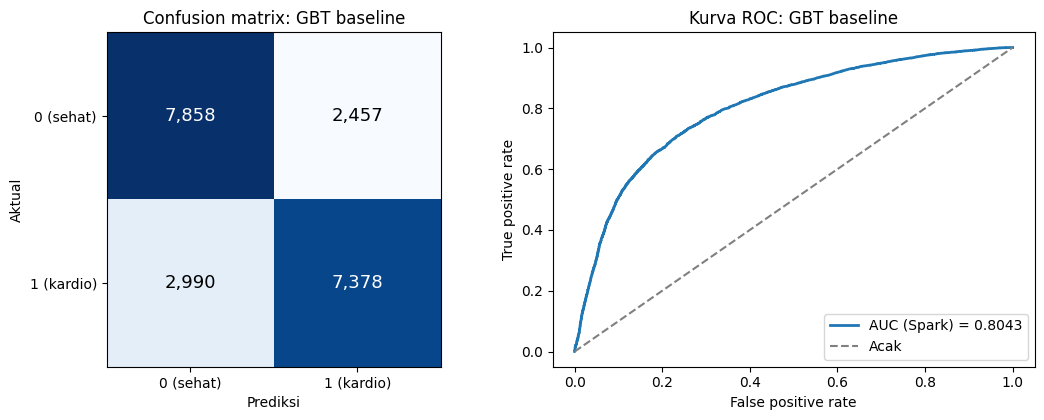

In [46]:
# 10.1 Evaluasi GBT baseline pada data uji
metrics_base, pred_base = evaluate_model(gbt_model, test_df)
print_report("GBT baseline (maxIter=75, maxDepth=3)", metrics_base)
plot_diagnostics(pred_base, metrics_base, "GBT baseline")

## 11. Hyperparameter tuning: `ParamGridBuilder` + `CrossValidator` (5-fold)

Artikel (bagian V) menyatakan tuning dilakukan dengan `ParamGridBuilder` dan `CrossValidator`, dan abstraknya menyebut validasi silang 5-fold, tetapi **ruang pencarian tidak dilaporkan**. Saya menentukan grid kecil di sekitar konfigurasi baseline (bagian 2). Pemilihan model memakai AUC-ROC (metrik utama artikel) pada data latih; data uji tidak disentuh sampai evaluasi akhir.

In [47]:
if RUN_CV:
    evaluator_auc = BinaryClassificationEvaluator(labelCol="label", rawPredictionCol="rawPrediction",
                                                  metricName="areaUnderROC")
    gbt_cv = GBTClassifier(featuresCol="features_scaled", labelCol="label", seed=SEED)

    param_grid = (ParamGridBuilder()
                  .addGrid(gbt_cv.maxDepth, GRID_MAX_DEPTH)
                  .addGrid(gbt_cv.maxIter, GRID_MAX_ITER)
                  .build())
    print(f"{len(param_grid)} kombinasi x {CV_FOLDS}-fold = {len(param_grid) * CV_FOLDS} pelatihan (+1 refit model terbaik)")

    cv = CrossValidator(estimator=gbt_cv, estimatorParamMaps=param_grid, evaluator=evaluator_auc,
                        numFolds=CV_FOLDS, seed=SEED, parallelism=2)

    t0 = time.perf_counter()
    cv_model = cv.fit(train_df)
    timings["cv_fit_s"] = time.perf_counter() - t0
    print(f"Waktu tuning : {timings['cv_fit_s'] / 60:.1f} menit")
else:
    print("RUN_CV = False, tuning dilewati.")

6 kombinasi x 5-fold = 30 pelatihan (+1 refit model terbaik)
Waktu tuning : 3.0 menit


In [48]:
if RUN_CV:
    rows = []
    for params, avg_auc in zip(param_grid, cv_model.avgMetrics):
        row = {p.name: v for p, v in params.items()}
        row["cv_auc_roc"] = avg_auc
        rows.append(row)
    cv_results = pd.DataFrame(rows).sort_values("cv_auc_roc", ascending=False).reset_index(drop=True)
    display(cv_results.round(4))

    # indeks terbaik yang sama argmax rata-rata metrik antar-fold)
    best_idx = int(np.argmax(cv_model.avgMetrics))
    best_params = {p.name: int(v) for p, v in param_grid[best_idx].items()}
    print("Hiyperparameter terbaik (berdasarkan rata-rata AUC 5-fold):", best_params)

,maxDepth,maxIter,cv_auc_roc
0,3,75,0.8008
1,3,50,0.8002
2,5,50,0.7999
3,5,75,0.7992
4,7,50,0.7943
5,7,75,0.7929


Hiyperparameter terbaik (berdasarkan rata-rata AUC 5-fold): {'maxDepth': 3, 'maxIter': 75}


## 12. Evaluasi model hasil tuning

Model terbaik dari `CrossValidator` (otomatis di-*refit* pada seluruh data latih) dievaluasi pada data uji yang sama.

=== GBT tuned {'maxDepth': 3, 'maxIter': 75} ===
Test Area Under ROC : 0.8043
Area Under PR       : 0.7889
Accuracy            : 0.7366
Precision           : 0.7502
Recall              : 0.7116
F1-score            : 0.7304
Confusion matrix    : [[7858, 2457], [2990, 7378]]   (n = 20,683)


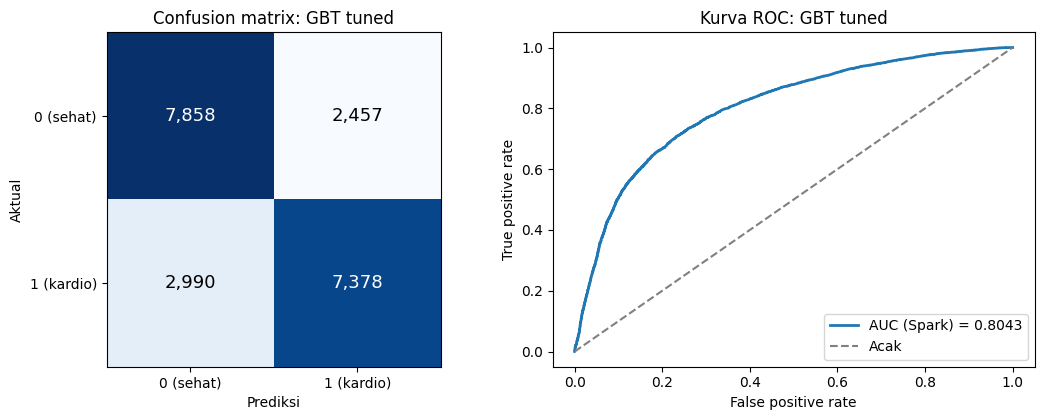

In [49]:
if RUN_CV:
    best_model = cv_model.bestModel
    metrics_tuned, pred_tuned = evaluate_model(best_model, test_df)
    print_report(f"GBT tuned {best_params}", metrics_tuned)
    plot_diagnostics(pred_tuned, metrics_tuned, "GBT tuned")
else:
    best_model, metrics_tuned = gbt_model, None
    print("Tuning dilewati; model akhir = baseline.")

## 13. Perbandingan dengan hasil artikel

Tabel membandingkan hasil replikasi dengan angka GBT pada **Tabel 3 artikel**. Kolom tambahan "Artikel (dihitung ulang dari CM)" memuat metrik yang saya hitung dari *confusion matrix* GBT pada Gambar 7 artikel, karena precision dan recall GBT pada Tabel 3 ternyata tidak cocok dengan *confusion matrix* tersebut (penjelasan di bagian 15.2, butir 2).

,Artikel,Artikel (dihitung ulang dari CM),Replikasi: GBT baseline,Replikasi: GBT tuned,Selisih baseline - artikel
AUC-ROC (%),80.02,NaN,80.43,80.43,0.41
Accuracy (%),73.20,73.20,73.66,73.66,0.46
Precision (%),76.79,74.28,75.02,75.02,-1.77
Recall (%),66.10,70.44,71.16,71.16,5.06
F1-score (%),71.05,72.31,73.04,73.04,1.99


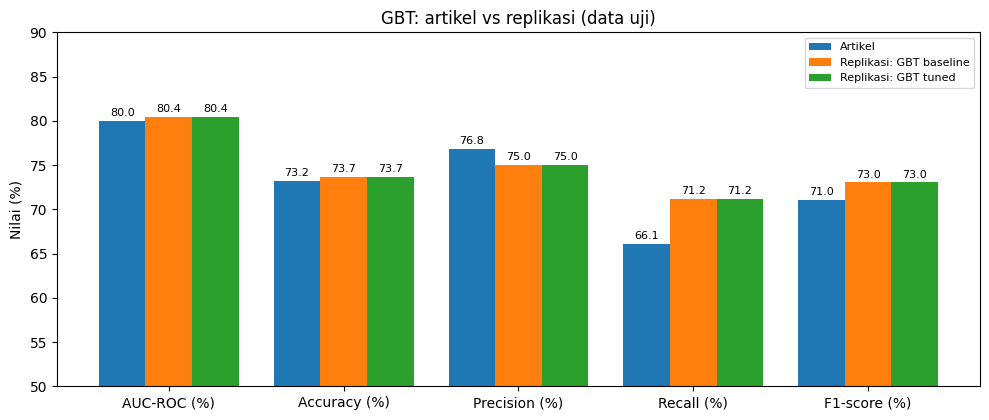


Ukuran data uji: replikasi = 20,683 | artikel = 13,703


In [50]:
def as_pct_row(m):
    return {"AUC-ROC (%)": m.get("auc_roc", np.nan) * 100 if m.get("auc_roc") is not None else np.nan,
            "Accuracy (%)": m["accuracy"] * 100, "Precision (%)": m["precision"] * 100,
            "Recall (%)": m["recall"] * 100, "F1-score (%)": m["f1"] * 100}


paper_from_cm = metrics_from_cm(np.array([[PAPER_GBT_CM["tn"], PAPER_GBT_CM["fp"]],
                                          [PAPER_GBT_CM["fn"], PAPER_GBT_CM["tp"]]]))
paper_from_cm["auc_roc"] = None

comparison = pd.DataFrame({
    "Artikel": PAPER_GBT_TABLE3,
    "Artikel (dihitung ulang dari CM)": as_pct_row(paper_from_cm),
    "Replikasi: GBT baseline": as_pct_row(metrics_base),
})
if metrics_tuned is not None:
    comparison["Replikasi: GBT tuned"] = as_pct_row(metrics_tuned)

comparison["Selisih baseline - artikel"] = comparison["Replikasi: GBT baseline"] - comparison["Artikel"]
display(comparison.round(2))

# Visualisasi Grafik
plot_cols = [c for c in ["Artikel", "Replikasi: GBT baseline", "Replikasi: GBT tuned"] if c in comparison]
x = np.arange(len(comparison.index))
w = 0.8 / len(plot_cols)
fig, ax = plt.subplots(figsize=(10, 4.3))
for i, col in enumerate(plot_cols):
    bars = ax.bar(x + i * w - 0.4 + w / 2, comparison[col], w, label=col)
    ax.bar_label(bars, fmt="%.1f", fontsize=8, padding=2)
ax.set_xticks(x); ax.set_xticklabels(comparison.index)
ax.set_ylabel("Nilai (%)"); ax.set_ylim(50, 90)
ax.set_title("GBT: artikel vs replikasi (data uji)")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

print(f"\nUkuran data uji: replikasi = {metrics_base['n']:,} | artikel = {PAPER_TEST_SIZE:,}")

## 14. Kepentingan fitur

Analisis tambahan (tidak ada pada artikel): `featureImportances` dari model akhir untuk melihat fitur yang paling berpengaruh pada prediksi.

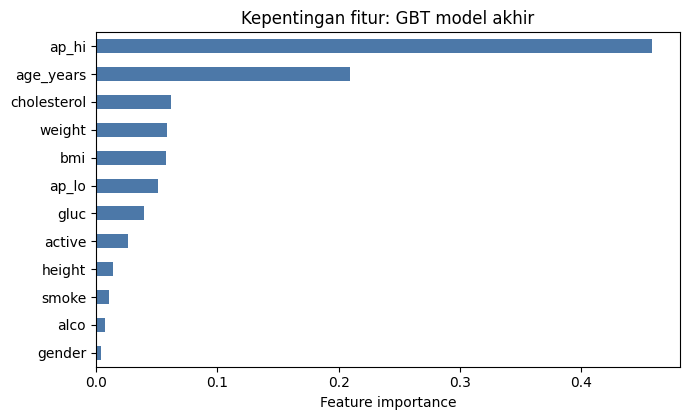

,importance
ap_hi,0.4583
age_years,0.2097
cholesterol,0.0622
weight,0.0582
bmi,0.0581
ap_lo,0.0508
gluc,0.0398
active,0.0263
height,0.0140
smoke,0.0111


In [51]:
final_model = best_model
importances = pd.Series(final_model.featureImportances.toArray(), index=FEATURE_COLS).sort_values()

ax = importances.plot.barh(figsize=(7, 4.3), color="#4c78a8")
ax.set_xlabel("Feature importance")
ax.set_title("Kepentingan fitur: GBT model akhir")
plt.tight_layout()
plt.show()
display(importances.sort_values(ascending=False).round(4).to_frame("importance"))

## 15. Perbedaan terhadap artikel, inkonsistensi artikel, dan panduan analisis

### 15.1 Perbedaan replikasi ini terhadap artikel

| Aspek | Artikel | Replikasi ini | Alasan / dampak |
|---|---|---|---|
| Jumlah model | 5 (LR, DT, SVM, RF, GBT) | 1 (GBT) | Skema replikasi parsial |
| Versi Spark | 2.4.7 | PySpark 3.5.x (lihat keluaran bagian 1.2) | Spark 2.4.7 tidak kompatibel dengan Python/Java Colab. Implementasi GBT pada Spark 3.x dapat berbeda sedikit (mis. perbaikan internal) sehingga angka bisa bergeser tipis |
| Lingkungan | Core i5 4 inti, RAM 16 GB, Anaconda | Google Colab, `local[*]` | Sama-sama mode lokal; kemampuan terdistribusi tidak diuji |
| Dataset | Kaggle, 70.000 baris | Dataset Kaggle yang sama | Versi berkas pada Kaggle dapat berbeda dari yang dipakai penulis |
| Pembersihan | Hapus `id`, hapus duplikat, "ganti nilai aneh" (tanpa rincian) | Aturan rentang + median (bagian 6) | Rincian tidak dilaporkan; **pengaruh terbesar** pada selisih hasil, termasuk ukuran data uji |
| Fitur baru | "Feature extraction" (tanpa rincian) | `age_years`, `bmi` | Asumsi |
| Pembagian data | 70/30, tanpa *seed* | 70/30, `seed=42` | Hasil artikel tidak dapat direproduksi persis karena *seed* tidak diketahui |
| Hiperparameter baseline | `maxIter=75`, `maxDepth=3` | Sama | Dari Gambar 7 artikel |
| Tuning | `ParamGridBuilder` + `CrossValidator` 5-fold, grid tidak dilaporkan | Grid sendiri (bagian 2) | Asumsi |
| Perhitungan *confusion matrix* | `collect()` ke *driver* + `sklearn` | `groupBy().count()` di Spark | Hasil sama, lebih efisien |

### 15.2 Ketidakkonsistenan yang saya temukan pada artikel

1. **Ukuran data uji.** Jumlah seluruh elemen *confusion matrix* pada Gambar 3–7 adalah 5.237 + 1.660 + 2.012 + 4.794 = **13.703** untuk setiap model. Bila data uji adalah 30% dari 70.000 baris, seharusnya sekitar 21.000. Nilai 13.703 setara dengan total data sekitar 45.700 baris (13.703 / 0,3), yang berarti sekitar sepertiga baris kemungkinan dibuang pada saat pembersihan, tetapi artikel tidak menyebutkannya. Akibatnya, data uji replikasi ini hampir pasti lebih besar daripada data uji artikel.
2. **Precision dan recall GBT pada Tabel 3.** Untuk LR, DT, SVM, dan RF, metrik pada Tabel 3 cocok dengan *confusion matrix* masing-masing. Untuk GBT, *confusion matrix* Gambar 7 (TN=5.237, FP=1.660, FN=2.012, TP=4.794) menghasilkan *accuracy* 73,20% (cocok), tetapi *precision* 74,28%, *recall* 70,44%, dan F1 0,7231, sedangkan Tabel 3 mencatat 76,79%, 66,10%, dan 0,7105. Salah satu penyebab yang mungkin adalah angka Tabel 3 berasal dari proses lain (mis. setelah tuning) atau kesalahan penyalinan; hal ini tidak dapat dipastikan dari artikel.
3. **Hasil tuning tidak dilaporkan.** Gambar 7 menunjukkan `maxIter=75`, `maxDepth=3` dengan AUC 0,8002 dan *accuracy* 0,7320, sama dengan angka GBT pada Tabel 3. Artikel tidak menyatakan apakah angka ini sebelum atau sesudah tuning, dan tidak melaporkan parameter terbaik hasil `CrossValidator`.
4. **Kesalahan penulisan kecil:** "training (70%) and training (30%)" (seharusnya *testing*), rujukan "Figure 3" untuk distribusi kelas (seharusnya Gambar 1).

### 15.3 Panduan analisis hasil (lengkapi di laporan setelah notebook dijalankan)

- **Kedekatan dengan artikel:** seberapa jauh AUC-ROC dan *accuracy* baseline dari 0,8002 dan 73,20%? Kaitkan selisih dengan butir 15.1 (pembersihan, *seed*, versi Spark) dan butir 15.2 (ukuran data uji berbeda).
- **Efek tuning:** apakah AUC-ROC 5-fold terbaik lebih tinggi daripada konfigurasi baseline pada tabel `cv_results`, dan apakah selisihnya berarti dibandingkan variasi antar-*fold*? Apakah peningkatan di data latih bertahan pada data uji?
- ***Precision* vs *recall*:** pada ambang 0,5, mana yang lebih besar? Pada konteks klinis, *false negative* (pasien sakit terdeteksi sehat) biasanya lebih berisiko, sehingga *recall* patut dibahas.
- **Fitur penting:** apakah urutan kepentingan fitur (bagian 14) masuk akal secara medis (mis. tekanan sistolik, usia, kolesterol)?
- **Keterbatasan:** satu pembagian data dan satu *seed*; data hanya 70.000 baris sehingga mode lokal sudah cukup (aspek terdistribusi Spark tidak benar-benar diuji); nilai pada dataset tidak diverifikasi klinis.

## 16. Menyimpan hasil dan menutup sesi

Hasil utama disimpan ke `/content/results` agar tabel dan angka pada laporan dapat dihasilkan ulang dan dilampirkan.

In [52]:
def to_serializable(m):
    return None if m is None else {k: (float(v) if isinstance(v, (float, np.floating)) else int(v)) for k, v in m.items()}


run_summary = {
    "environment": {"python": sys.version.split()[0], "pyspark": pyspark.__version__, "spark": spark.version,
                    "java": java_ver, "cores": spark.sparkContext.defaultParallelism},
    "config": {"seed": SEED, "sample_fraction": SAMPLE_FRACTION, "outlier_strategy": OUTLIER_STRATEGY,
               "train_ratio": TRAIN_RATIO, "gbt_base": GBT_BASE, "cv_folds": CV_FOLDS,
               "grid_max_depth": GRID_MAX_DEPTH, "grid_max_iter": GRID_MAX_ITER, "run_cv": RUN_CV},
    "data": {"rows_raw": int(n_raw), "duplicates_dropped": int(n_dupes), "rows_clean": int(n_clean),
             "rows_train": int(n_train), "rows_test": int(n_test)},
    "best_params": best_params if RUN_CV else None,
    "metrics_baseline": to_serializable(metrics_base),
    "metrics_tuned": to_serializable(metrics_tuned),
    "timings_seconds": {k: round(v, 2) for k, v in timings.items()},
}

with open(f"{OUTPUT_DIR}/run_summary.json", "w") as f:
    json.dump(run_summary, f, indent=2)
comparison.round(4).to_csv(f"{OUTPUT_DIR}/comparison_vs_paper.csv")
if RUN_CV:
    cv_results.to_csv(f"{OUTPUT_DIR}/cv_results.csv", index=False)

print("Tersimpan di", OUTPUT_DIR, "->", sorted(os.listdir(OUTPUT_DIR)))
print("Waktu eksekusi (detik):", {k: round(v, 1) for k, v in timings.items()})

Tersimpan di /content/results -> ['comparison_vs_paper.csv', 'cv_results.csv', 'run_summary.json']
Waktu eksekusi (detik): {'gbt_baseline_fit_s': 6.3, 'cv_fit_s': 179.6}


In [53]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [54]:
spark.stop()
print("SparkSession dihentikan.")

SparkSession dihentikan.


## Atribusi dan integritas akademik

- Alur kerja, hiperparameter baseline, dan metrik mengacu pada Gupta & Kumari (2021) (lihat sitasi di awal notebook); bagian yang tidak dirinci artikel ditandai **[asumsi]**.
- Dataset: Kaggle, `sulianova/cardiovascular-disease-dataset`.
- Dokumentasi yang dipakai: Apache Spark MLlib (`GBTClassifier`, `CrossValidator`, `BinaryClassificationEvaluator`).
- Penggunaan *generative AI*: *(isi sesuai kebijakan dosen, sebutkan bagian yang dibantu, mis. kerangka notebook)*.